In [1]:
import pandas as pd

In [3]:
# 1. Load data
df = pd.read_csv('crowdfunding_world_data.csv')
print("Raw shape:", df.shape)                     
n_raw = len(df) 

# 2. Remove duplicates
df = df.drop_duplicates()

# 3. Remove columns that are completely empty
df = df.dropna(axis=1, how='all')

# 4. Convert dates
for col in ['Start_Date', 'End_Date']:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# 5. Convert numeric columns
for col in ['Funding', 'Target', 'Duration', 'Success']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 6. Remove rows missing essential information
df = df.dropna(subset=['Funding', 'Target', 'Success'])

# 7. Remove invalid values
df = df[(df['Funding'] >= 0) & (df['Target'] > 0)]
df = df[df['Success'].isin([0, 1])]

# 8. Reset index
df = df.reset_index(drop=True)

# 9. Check results
print("Cleaned shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())


Raw shape: (15006, 217)
Cleaned shape: (15006, 217)
Missing values: 0
Duplicates: 0


In [4]:
# Pre-launch feature set (avoid data leakage)
# Variables observed only after/during the campaign are excluded
country_cols = df.columns[df.columns.get_loc('Albania'):df.columns.get_loc('Zimbabwe') + 1].tolist()
leakage_cols = (['Funding', 'Funding_IHS', 'Backers', 'Updates', 'Staff_Pick',
                 'EU_Backers_Tot', 'EU_Backers_Share'] + country_cols)

pre_launch_cols = ['Target', 'Duration', 'Category', 'Images_Bool', 'Videos_Bool',
                   'Video_Header', 'Rewards', 'Prev_Success', 'Backed', 'Description', 'EU_Bool']

df_model = df[pre_launch_cols + ['Success']].copy()
print(f"Excluded {len(leakage_cols)} post-launch variables; "
      f"{len(pre_launch_cols)} pre-launch predictors retained.")

Excluded 197 post-launch variables; 11 pre-launch predictors retained.


In [5]:
print(df.columns.to_list())

['ID', 'Start_Date', 'End_Date', 'Duration', 'Category', 'Category_Kickstarter', 'Success', 'Funding', 'Funding_IHS', 'Target', 'Target_IHS', 'Staff_Pick', 'Backers', 'Video_Header', 'Videos_Bool', 'Images_Bool', 'Description', 'Rewards', 'Prev_Success', 'Backed', 'Updates', 'Links', 'Albania', 'American Samoa', 'Andorra', 'Angola', 'Antarctica', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'British Virgin Islands', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Caribbean Netherlands', 'Cayman Islands', 'Central African Republic', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cuba', 'Curaçao', 'Cyprus', 'Czechia', 'Democratic Republic of Congo', 'Denmark', 'Dominica', 'Dominican Republic', 'East Timor', 'Ecuador', 'Egypt', 'El Salvador', 'Estoni

In [6]:
# Success distribution
print(df['Success'].value_counts())
print(df['Success'].value_counts(normalize=True) * 100)

Success
1    12504
0     2502
Name: count, dtype: int64
Success
1    83.326669
0    16.673331
Name: proportion, dtype: float64


In [7]:
# Numerical variables
cols = [
    'Duration', 'Funding', 'Target',
    'Backers', 'Rewards', 'Updates',
    'Prev_Success', 'Backed'
]

display(df[cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Duration,15006.0,30.189324,11.947383,1.00,23.000,30.000,31.0000,60.0
Funding,15006.0,19272.205857,359104.955725,0.00,1606.070,4297.560,11847.2575,41754153.0
Target,15006.0,9422.992764,118311.459647,0.75,754.295,2959.125,7777.0000,13728690.0
Backers,15006.0,187.077902,1715.488266,10.00,29.000,71.000,177.0000,185341.0
Rewards,15006.0,8.029122,5.950805,1.00,4.000,7.000,10.0000,99.0
Updates,15006.0,3.590164,4.358903,0.00,1.000,2.000,5.0000,51.0
Prev_Success,15006.0,2.796082,5.321268,0.00,0.000,0.000,3.0000,31.0
Backed,15006.0,25.903972,70.686942,0.00,0.000,3.000,18.0000,897.0


In [8]:
display(df['Category_Kickstarter'].value_counts())
display(df.groupby('Category')['Success'].agg(['count', 'mean']))

Category_Kickstarter
games           4485
comics          1929
publishing      1657
art             1364
design          1349
film & video    1219
technology       745
music            715
fashion          615
food             351
crafts           188
photography      178
theater          101
dance             63
journalism        47
Name: count, dtype: int64

,count,mean
Category,,
Creative Arts,3645,0.880384
Design,1964,0.820774
Food,351,0.635328
Literature & Journalism,1704,0.843310
Media & Entertainment,7342,0.820349


In [9]:
display(df['Category'].value_counts())
display(df.groupby('Category')['Success'].agg(['count', 'mean']))

Category
Media & Entertainment      7342
Creative Arts              3645
Design                     1964
Literature & Journalism    1704
Food                        351
Name: count, dtype: int64

,count,mean
Category,,
Creative Arts,3645,0.880384
Design,1964,0.820774
Food,351,0.635328
Literature & Journalism,1704,0.843310
Media & Entertainment,7342,0.820349


In [10]:
import numpy as np

# Relationship between funding goal and campaign duration
# Target is highly right-skewed, so we use the log of the funding goal
log_target = np.log(df['Target'])

r_log = log_target.corr(df['Duration'])
r_raw = df['Target'].corr(df['Duration'])

print(f"Correlation (log Target, Duration): r = {r_log:.2f}")
print(f"Correlation (raw Target, Duration): r = {r_raw:.2f}  (distorted by extreme goals)")

Correlation (log Target, Duration): r = 0.32
Correlation (raw Target, Duration): r = 0.04  (distorted by extreme goals)


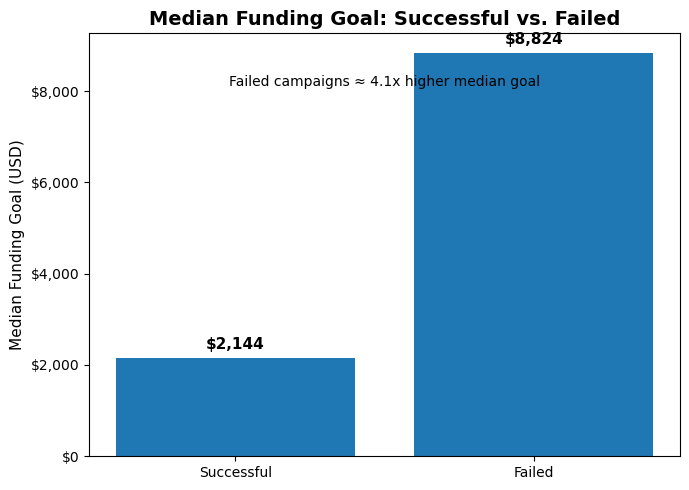

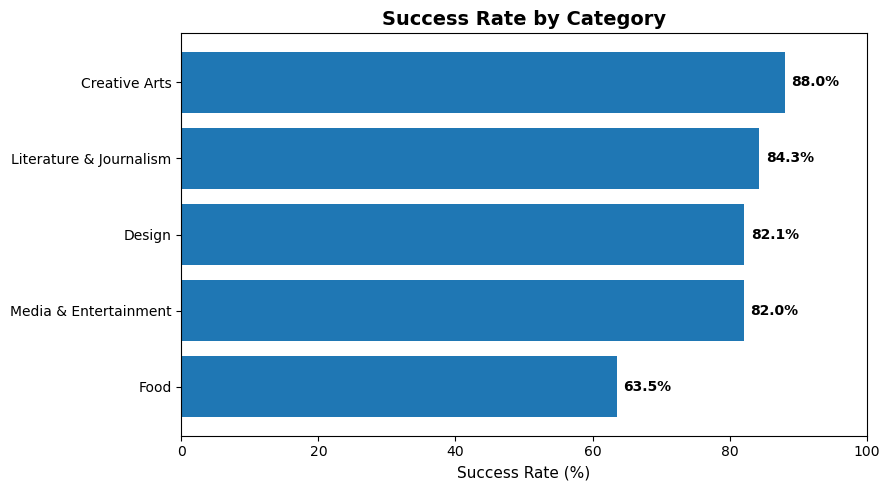

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ========= Chart 1: Median Funding Goal: Successful vs. Failed =========
goal_summary = df.groupby('Success')['Target'].median()
goal_summary = pd.Series({
    'Successful': goal_summary.loc[1],
    'Failed': goal_summary.loc[0]
})

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(goal_summary.index, goal_summary.values)

ax.set_title('Median Funding Goal: Successful vs. Failed', fontsize=14, weight='bold')
ax.set_ylabel('Median Funding Goal (USD)', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x:,.0f}'))

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 150, f'${h:,.0f}', ha='center', va='bottom', fontsize=11, weight='bold')

ratio = goal_summary['Failed'] / goal_summary['Successful']
ax.text(0.5, max(goal_summary.values) * 0.92, f'Failed campaigns ≈ {ratio:.1f}x higher median goal', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('chart_median_goal_success_vs_failed.png', dpi=300, bbox_inches='tight')
plt.show()

# ========= Chart 2: Success Rate by Category =========
cat_success = df.groupby('Category')['Success'].mean().mul(100).sort_values(ascending=False)

selected_categories = [
    'Creative Arts',
    'Literature & Journalism',
    'Design',
    'Media & Entertainment',
    'Food'
]
cat_success = cat_success.reindex(selected_categories).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cat_success.index, cat_success.values)

ax.set_title('Success Rate by Category', fontsize=14, weight='bold')
ax.set_xlabel('Success Rate (%)', fontsize=11)
ax.set_xlim(0, 100)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.savefig('chart_success_rate_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

## Step 1: Variable Construction

We construct the predictors for the main model using pre-launch information only:

- **Log2_Target**: log base 2 of the funding goal. Each one-unit increase represents a doubling of the goal, which handles the strong right skew of `Target`.
- **Prev_Success_Bool**: 1 if the creator has at least one previous successful campaign, 0 otherwise.
- **Category dummies**: four indicators for the five category groups, with Media & Entertainment (the largest group) as the reference category.

In [12]:
import numpy as np
import pandas as pd

# Keep only pre-launch predictors used in the main model, plus the outcome
df_model = df[['Target', 'Duration', 'Category', 'Images_Bool', 'Videos_Bool',
               'Rewards', 'Prev_Success', 'Success']].copy()

# Log2 of the funding goal: one unit = doubling the goal
df_model['Log2_Target'] = np.log2(df_model['Target'])

# Indicator for creators with at least one previous successful campaign
df_model['Prev_Success_Bool'] = (df_model['Prev_Success'] > 0).astype(int)

# Category dummies with clean column names
cat_dummies = pd.get_dummies(df_model['Category'], prefix='Cat', dtype=int)
cat_dummies.columns = (cat_dummies.columns
                       .str.replace(' & ', '_', regex=False)
                       .str.replace(' ', '_', regex=False))

# Drop the reference category (Media & Entertainment)
cat_dummies = cat_dummies.drop(columns='Cat_Media_Entertainment')
df_model = pd.concat([df_model, cat_dummies], axis=1)

# Quick checks
print("Modeling data shape:", df_model.shape)
print("\nContinuous predictors:")
print(df_model[['Log2_Target', 'Duration', 'Rewards']].describe().round(2))
print("\nPrev_Success_Bool:")
print(df_model['Prev_Success_Bool'].value_counts())
print("\nCategory dummies (count of 1s):")
print(cat_dummies.sum())
print("\nColumns:", df_model.columns.tolist())

Modeling data shape: (15006, 14)

Continuous predictors:
       Log2_Target  Duration   Rewards
count     15006.00  15006.00  15006.00
mean         11.23     30.19      8.03
std           2.42     11.95      5.95
min          -0.42      1.00      1.00
25%           9.56     23.00      4.00
50%          11.53     30.00      7.00
75%          12.92     31.00     10.00
max          23.71     60.00     99.00

Prev_Success_Bool:
Prev_Success_Bool
0    7994
1    7012
Name: count, dtype: int64

Category dummies (count of 1s):
Cat_Creative_Arts            3645
Cat_Design                   1964
Cat_Food                      351
Cat_Literature_Journalism    1704
dtype: int64

Columns: ['Target', 'Duration', 'Category', 'Images_Bool', 'Videos_Bool', 'Rewards', 'Prev_Success', 'Success', 'Log2_Target', 'Prev_Success_Bool', 'Cat_Creative_Arts', 'Cat_Design', 'Cat_Food', 'Cat_Literature_Journalism']


**Result.** All 15,006 campaigns are retained. The median Log2_Target is 11.53 (about $2,950), and the log transformation compresses the extreme goals (from $0.75 to $13.7M) into a range of -0.42 to 23.71. About 46.7% of campaigns are run by creators with at least one previous success, giving a well-balanced indicator. The four category dummies plus the reference group (Media & Entertainment, n = 7,342) account for all observations.

## Step 2: Stratified Train-Test Split

We split the data 80/20, stratified on `Success` so that both sets preserve the 83.3% / 16.7% class ratio. The split is fixed with `random_state=42` and shared across the team, so all models are evaluated on the same test set. The split is done before centering, so that centering constants are computed from the training set only.

In [13]:
from sklearn.model_selection import train_test_split

# Stratified 80/20 split, fixed seed shared across the team
train_df, test_df = train_test_split(
    df_model,
    test_size=0.2,
    stratify=df_model['Success'],
    random_state=42
)

# Check sizes and class balance in each set
print("Train shape:", train_df.shape)
print("Test shape: ", test_df.shape)
print("\nSuccess rate (train): {:.2%}".format(train_df['Success'].mean()))
print("Success rate (test):  {:.2%}".format(test_df['Success'].mean()))
print("\nFailed campaigns - train: {}, test: {}".format(
    (train_df['Success'] == 0).sum(), (test_df['Success'] == 0).sum()))

Train shape: (12004, 14)
Test shape:  (3002, 14)

Success rate (train): 83.33%
Success rate (test):  83.31%

Failed campaigns - train: 2001, test: 501


**Result.** The training set contains 12,004 campaigns and the test set 3,002. Stratification preserves the class ratio almost exactly (83.33% success in training vs. 83.31% in test), leaving 2,001 failed campaigns for training and 501 for evaluation.

## Step 3: Centering and Interaction Term

Duration is rescaled to 10-day units so that its odds ratio is directly interpretable per 10 days. Log2_Target and Duration_10 are then mean-centered using training-set means only, and the same constants are applied to the test set. Centering makes each main effect interpretable at the average level of the other variable and reduces collinearity between the main effects and their interaction.

In [14]:
# Rescale duration to 10-day units
train_df = train_df.copy()
test_df = test_df.copy()
train_df['Duration_10'] = train_df['Duration'] / 10
test_df['Duration_10'] = test_df['Duration'] / 10

# Centering constants from the training set only
mean_log_target = train_df['Log2_Target'].mean()
mean_duration_10 = train_df['Duration_10'].mean()
print("Training mean of Log2_Target: {:.4f} (about ${:,.0f})".format(
    mean_log_target, 2 ** mean_log_target))
print("Training mean of Duration:    {:.2f} days".format(mean_duration_10 * 10))

# Apply the same constants to both sets
for d in [train_df, test_df]:
    d['Log2_Target_c'] = d['Log2_Target'] - mean_log_target
    d['Duration_10_c'] = d['Duration_10'] - mean_duration_10
    d['Target_x_Duration'] = d['Log2_Target_c'] * d['Duration_10_c']

# Check: centered means should be ~0 in train, close to 0 in test
print("\nCentered means (train):")
print(train_df[['Log2_Target_c', 'Duration_10_c']].mean().round(4))
print("\nCentered means (test):")
print(test_df[['Log2_Target_c', 'Duration_10_c']].mean().round(4))

# Collinearity check: uncentered vs. centered interaction
raw_product = train_df['Log2_Target'] * train_df['Duration_10']
print("\nCorrelation with main effects (training set):")
print("  Uncentered product vs Log2_Target: {:.2f}".format(
    raw_product.corr(train_df['Log2_Target'])))
print("  Uncentered product vs Duration:    {:.2f}".format(
    raw_product.corr(train_df['Duration_10'])))
print("  Centered product vs Log2_Target_c: {:.2f}".format(
    train_df['Target_x_Duration'].corr(train_df['Log2_Target_c'])))
print("  Centered product vs Duration_10_c: {:.2f}".format(
    train_df['Target_x_Duration'].corr(train_df['Duration_10_c'])))

Training mean of Log2_Target: 11.2221 (about $2,389)
Training mean of Duration:    30.17 days

Centered means (train):
Log2_Target_c    0.0
Duration_10_c    0.0
dtype: float64

Centered means (test):
Log2_Target_c    0.0186
Duration_10_c    0.0104
dtype: float64

Correlation with main effects (training set):
  Uncentered product vs Log2_Target: 0.65
  Uncentered product vs Duration:    0.91
  Centered product vs Log2_Target_c: -0.13
  Centered product vs Duration_10_c: -0.02


**Result.** The training-set centering constants are 11.22 for Log2_Target (a geometric-mean goal of about $2,389) and 30.17 days for Duration. Centered means are exactly zero in the training set and close to zero in the test set (0.019 and 0.010), as expected when training constants are applied unchanged. Centering substantially reduces collinearity: the correlation between the interaction term and Duration falls from 0.91 to -0.02, and between the interaction term and Log2_Target from 0.65 to -0.13. Main effects can therefore be interpreted as effects for a campaign with a typical goal and duration.

## Step 4: Main Logistic Regression Model

We fit the main logistic regression on the training set using `statsmodels`, which provides standard errors and p-values for hypothesis testing. The specification follows the PoC:

logit P(Success = 1) = β₀ + β₁·Log2_Target_c + β₂·Duration_10_c + β₃·(Log2_Target_c × Duration_10_c) + γ′X

where X includes the four category dummies (reference: Media & Entertainment), image and video indicators, the number of reward tiers, and the previous-success indicator. No class weights are used, so that predicted probabilities remain calibrated.

In [15]:
import statsmodels.api as sm

# Predictors for the main model
predictors = [
    'Log2_Target_c', 'Duration_10_c', 'Target_x_Duration',  # H1, H2, H3
    'Prev_Success_Bool',                                     # H4
    'Images_Bool', 'Videos_Bool', 'Rewards',                 # H5
    'Cat_Creative_Arts', 'Cat_Design', 'Cat_Food',
    'Cat_Literature_Journalism'                              # category controls
]

X_train = sm.add_constant(train_df[predictors])
y_train = train_df['Success']

# Fit the main logistic model on the training set
logit_full = sm.Logit(y_train, X_train).fit()
print(logit_full.summary())

Optimization terminated successfully.
         Current function value: 0.349621
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                Success   No. Observations:                12004
Model:                          Logit   Df Residuals:                    11992
Method:                           MLE   Df Model:                           11
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.2241
Time:                        22:00:02   Log-Likelihood:                -4196.8
converged:                       True   LL-Null:                       -5409.1
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         0.9636      0.096     10.050      0.000       0.

**Result.** The model converges and is jointly significant (LLR p < 0.001), with a McFadden pseudo R² of 0.224.

- **H1 (funding goal) is supported.** Log2_Target has a coefficient of -0.474 (p < 0.001): doubling the goal reduces the odds of success by about 38%.
- **H2 (duration) is supported.** For a campaign with an average goal, each additional 10 days reduces the odds of success by about 15% (coef = -0.164, p < 0.001).
- **H3 (goal × duration) is supported.** The interaction is negative and significant (coef = -0.035, p = 0.004): the duration penalty grows as the goal rises. For a goal twice the average, the duration coefficient becomes -0.199.
- **H4 (creator track record) is strongly supported.** Creators with a previous success have about 3.1 times the odds of success of first-time creators (coef = 1.145, p < 0.001), the largest effect in the model.
- **H5 (presentation) is partially supported.** Each additional reward tier raises the odds by about 10% (p < 0.001), but image and video indicators are not significant. Images show little variation (91% of campaigns include them), which limits identification.

Category effects change once campaign design is controlled for. Creative Arts has the highest raw success rate (88%) but a significantly negative coefficient (coef = -0.340, p < 0.001), suggesting its raw advantage comes mainly from lower goals rather than the category itself. Food's low raw success rate (63.5%) is not significant after controls (p = 0.099).

## Step 5: Odds Ratio Table

We convert the coefficients into odds ratios, exp(β), with 95% confidence intervals obtained by exponentiating the coefficient intervals. An odds ratio above 1 indicates higher odds of success; below 1 indicates lower odds. Log2_Target is interpreted per doubling of the goal, Duration_10_c per 10 additional days, and Rewards per additional tier.

In [16]:
# Odds ratios with 95% confidence intervals
ci = logit_full.conf_int()
or_table = pd.DataFrame({
    'Coef': logit_full.params,
    'Odds_Ratio': np.exp(logit_full.params),
    'CI_Lower': np.exp(ci[0]),
    'CI_Upper': np.exp(ci[1]),
    'p_value': logit_full.pvalues
}).drop(index='const')

# Significance stars
def stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    return ''

or_table['Sig'] = or_table['p_value'].apply(stars)

# Map each predictor to its hypothesis
hypothesis_map = {
    'Log2_Target_c': 'H1', 'Duration_10_c': 'H2', 'Target_x_Duration': 'H3',
    'Prev_Success_Bool': 'H4', 'Images_Bool': 'H5', 'Videos_Bool': 'H5',
    'Rewards': 'H5', 'Cat_Creative_Arts': 'Control', 'Cat_Design': 'Control',
    'Cat_Food': 'Control', 'Cat_Literature_Journalism': 'Control'
}
or_table['Hypothesis'] = or_table.index.map(hypothesis_map)

or_table = or_table.round(3)
display(or_table)

# Export for teammates (forest plot, slides, report)
or_table.to_csv('or_table_main_model.csv')
print("Saved: or_table_main_model.csv")

,Coef,Odds_Ratio,CI_Lower,CI_Upper,p_value,Sig,Hypothesis
Log2_Target_c,-0.474,0.623,0.603,0.643,0.000,***,H1
Duration_10_c,-0.164,0.848,0.803,0.897,0.000,***,H2
Target_x_Duration,-0.035,0.966,0.943,0.989,0.004,**,H3
Prev_Success_Bool,1.145,3.142,2.738,3.606,0.000,***,H4
Images_Bool,0.091,1.096,0.920,1.304,0.304,,H5
Videos_Bool,-0.046,0.955,0.825,1.107,0.545,,H5
Rewards,0.098,1.103,1.087,1.119,0.000,***,H5
Cat_Creative_Arts,-0.340,0.712,0.612,0.829,0.000,***,Control
Cat_Design,-0.046,0.955,0.810,1.125,0.581,,Control
Cat_Food,-0.236,0.790,0.597,1.045,0.099,,Control


Saved: or_table_main_model.csv


**Result.** All significant predictors have 95% confidence intervals that lie entirely on one side of 1. The goal effect is estimated precisely (OR = 0.623, CI 0.603–0.643), and the creator track-record effect remains large even at its lower bound (OR = 3.142, CI 2.738–3.606). Each additional reward tier raises the odds by about 10% (CI 1.087–1.119). The intervals for images, videos, Design and Literature & Journalism all include 1. Food has the widest interval (0.597–1.045), reflecting its small sample (n = 351).

## Step 6: Export Files for the Team

We export the shared train/test split with all constructed variables, the main model's predicted probabilities on the test set (for evaluation and threshold selection), and the centering constants and coefficients (for the prototype). This ensures that all team members work from the same data and model.

In [17]:
import json

# 1. Shared train/test split with all constructed variables
train_df.to_csv('train_data.csv', index=True)
test_df.to_csv('test_data.csv', index=True)

# 2. Predicted probabilities of the main model on the test set
X_test = sm.add_constant(test_df[predictors])
test_pred = pd.DataFrame({
    'Success': test_df['Success'],
    'Pred_Prob_Logit': logit_full.predict(X_test)
}, index=test_df.index)
test_pred.to_csv('test_predictions_logit.csv', index=True)

# 3. Model specification for the prototype
model_spec = {
    'centering': {
        'mean_log2_target': mean_log_target,
        'mean_duration_10': mean_duration_10
    },
    'predictors': predictors,
    'coefficients': logit_full.params.to_dict(),
    'notes': 'Duration is in 10-day units. Log2_Target = log2(goal in USD). '
             'Reference category: Media & Entertainment. '
             'Target_x_Duration = Log2_Target_c * Duration_10_c.'
}
with open('model_spec.json', 'w') as f:
    json.dump(model_spec, f, indent=2)

# Quick checks
print("Saved: train_data.csv", train_df.shape)
print("Saved: test_data.csv ", test_df.shape)
print("Saved: test_predictions_logit.csv", test_pred.shape)
print("Saved: model_spec.json")
print("\nMean predicted probability (test): {:.3f}".format(test_pred['Pred_Prob_Logit'].mean()))
print("Actual success rate (test):        {:.3f}".format(test_pred['Success'].mean()))

Saved: train_data.csv (12004, 18)
Saved: test_data.csv  (3002, 18)
Saved: test_predictions_logit.csv (3002, 2)
Saved: model_spec.json

Mean predicted probability (test): 0.832
Actual success rate (test):        0.833


**Result.** The shared files are exported: the train and test sets (18 columns each, including all constructed variables), the main model's test-set predictions, and the model specification. As an initial calibration check, the mean predicted probability on the test set (0.832) closely matches the observed success rate (0.833), confirming that the unweighted model produces unbiased probabilities on average. A full calibration curve is left to the diagnostics section.